In [3]:
%pip install mplfinance

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mplfinance as mpf

from pathlib import Path
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.style.use("default")

#2. Load Dataset and Select Reliance Stock

In [5]:
# Locate the existing financial dataset
possible_paths = [
    Path("data/financial_data.csv"),
    Path("FinancialDataAnalysis/data/financial_data.csv")
]

file_path = next((path for path in possible_paths if path.exists()), None)

if file_path is None:
    raise FileNotFoundError(
        "Place this notebook inside FinancialDataAnalysis, "
        "or extract the original ZIP file first."
    )

df = pd.read_csv(file_path)
df["Date"] = pd.to_datetime(df["Date"])

print("Dataset Shape:", df.shape)
print("Total Stocks:", df["Symbol"].nunique())

# Select Reliance stock
stock = df[df["Symbol"] == "RELIANCE.NS"].copy()
stock = stock.sort_values("Date")
stock.set_index("Date", inplace=True)

print("Reliance Records:", len(stock))
stock.head()

Dataset Shape: (130473, 8)
Total Stocks: 49
Reliance Records: 2681


,Adj Close,Close,High,Low,Open,Volume,Symbol
Date,,,,,,,
2016-01-01,218.997467,232.091934,232.903397,230.457565,230.823288,5416562,RELIANCE.NS
2016-01-04,214.672958,227.508835,231.737625,225.543015,229.726089,30170947,RELIANCE.NS
2016-01-05,216.797455,229.760376,230.869003,227.897430,228.651749,14946239,RELIANCE.NS
2016-01-06,222.631760,235.943558,237.360779,228.674606,230.320404,26759864,RELIANCE.NS
2016-01-07,218.544540,231.611908,234.983505,230.423279,233.394852,19739943,RELIANCE.NS


#3. Line Chart – Historical Closing Price

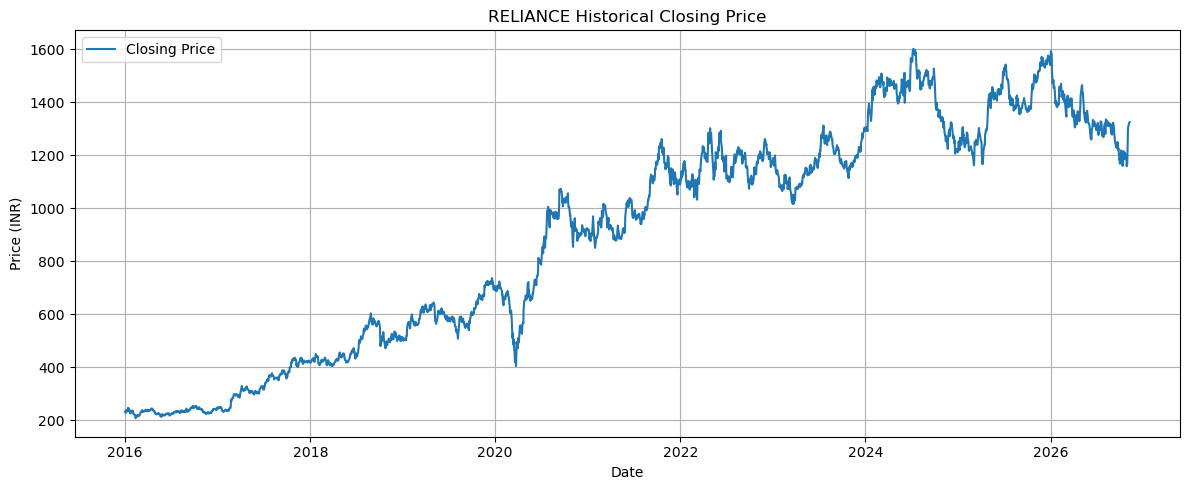

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(stock.index, stock["Close"], label="Closing Price")
plt.title("RELIANCE Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Price (INR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#4. Candlestick Chart


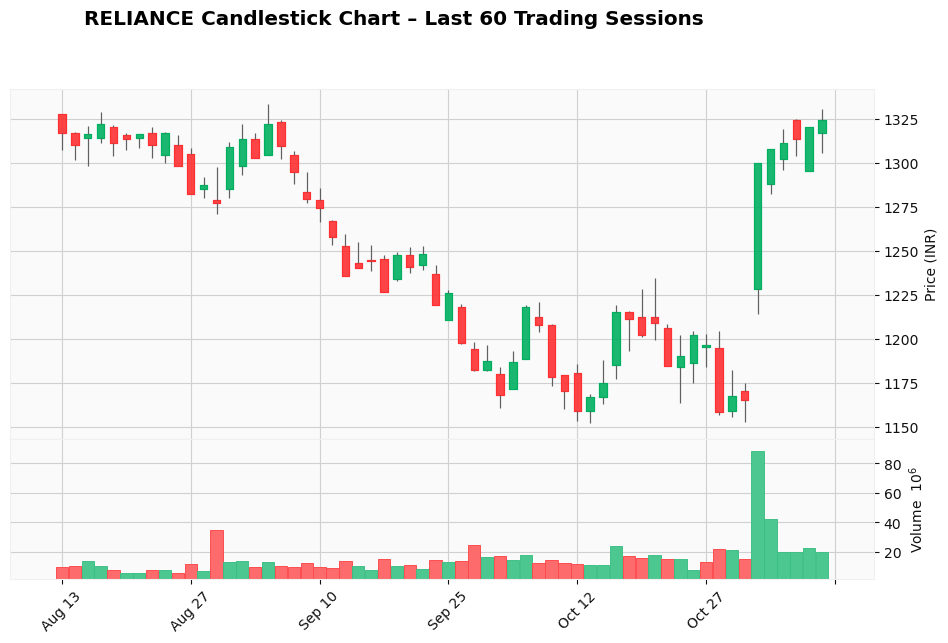

In [7]:
recent_stock = stock[["Open", "High", "Low", "Close", "Volume"]].tail(60)

mpf.plot(
    recent_stock,
    type="candle",
    style="yahoo",
    volume=True,
    title="RELIANCE Candlestick Chart – Last 60 Trading Sessions",
    ylabel="Price (INR)",
    figsize=(12, 7)
)

#5. Moving Averages

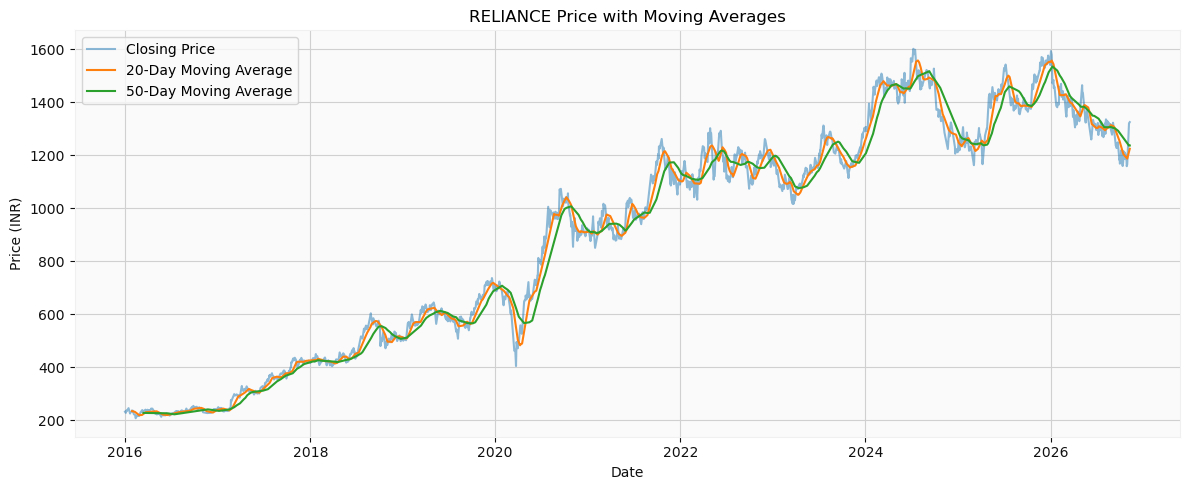

In [8]:
stock["MA20"] = stock["Close"].rolling(window=20).mean()
stock["MA50"] = stock["Close"].rolling(window=50).mean()

plt.figure(figsize=(12, 5))
plt.plot(stock.index, stock["Close"], label="Closing Price", alpha=0.5)
plt.plot(stock.index, stock["MA20"], label="20-Day Moving Average")
plt.plot(stock.index, stock["MA50"], label="50-Day Moving Average")

plt.title("RELIANCE Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (INR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#6. Seasonality Analysis – Average Monthly Returns

Average Monthly Returns (%):
Jan   -0.71
Feb    1.22
Mar    1.39
Apr    6.14
May   -1.71
Jun    3.11
Jul    4.62
Aug    2.15
Sep    0.54
Oct    0.62
Nov    2.16
Dec    0.05
Name: Adj Close, dtype: float64
Highest Average Return Month: Apr
Lowest Average Return Month: May


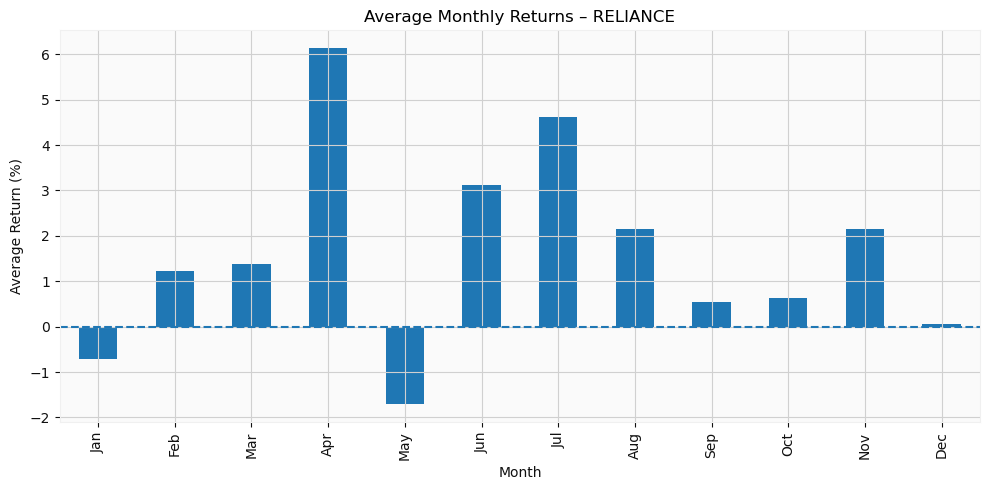

In [9]:
# Calculate monthly closing prices and percentage returns
monthly_prices = stock["Adj Close"].resample("ME").last()
monthly_returns = monthly_prices.pct_change() * 100
monthly_returns = monthly_returns.dropna()

# Find average return for each calendar month
seasonal_returns = monthly_returns.groupby(monthly_returns.index.month).mean()
seasonal_returns = seasonal_returns.reindex(range(1, 13))
seasonal_returns.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print("Average Monthly Returns (%):")
print(seasonal_returns.round(2))
print("Highest Average Return Month:", seasonal_returns.idxmax())
print("Lowest Average Return Month:", seasonal_returns.idxmin())

plt.figure(figsize=(10, 5))
seasonal_returns.plot(kind="bar")
plt.title("Average Monthly Returns – RELIANCE")
plt.xlabel("Month")
plt.ylabel("Average Return (%)")
plt.axhline(y=0, linestyle="--")
plt.tight_layout()
plt.show()

#7. Anomaly Detection – Unusual Daily Returns

Number of Anomalies: 34
             Adj Close  Daily_Return   Z_Score
Date                                          
2016-01-18  219.320984     -5.259490 -3.144644
2017-02-22  263.373993     10.963052  6.406750
2018-10-04  496.749695     -6.874935 -4.095774
2018-10-05  464.260101     -6.540436 -3.898830
2018-10-08  491.061798      5.772992  3.350983
2019-08-13  567.638855      9.693662  5.659368
2019-09-20  558.554810      6.386507  3.712204
2020-03-09  496.124573    -12.340670 -7.313852
2020-03-12  473.347748     -7.849680 -4.669678
2020-03-16  452.285370     -8.106393 -4.820824


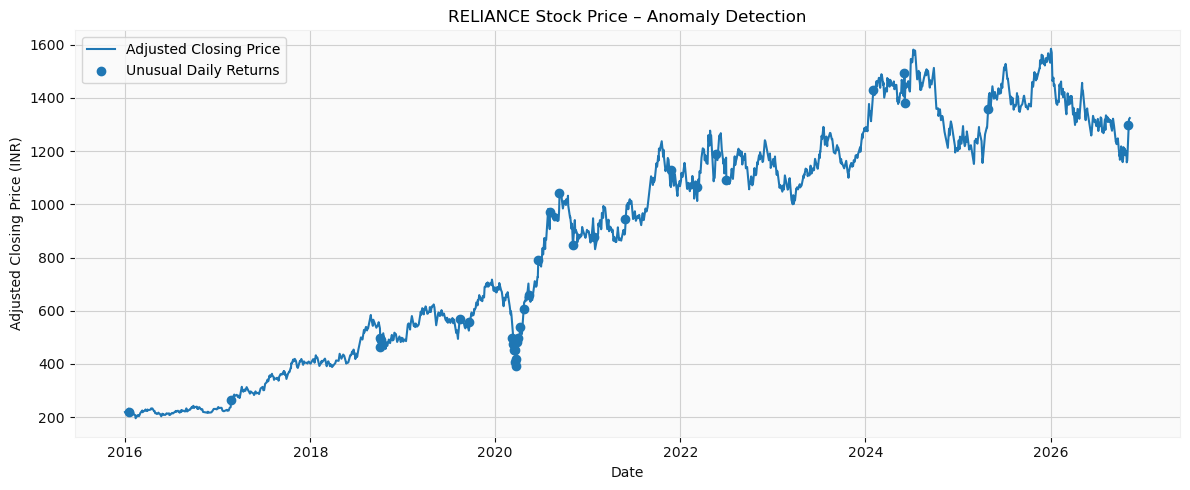

In [10]:
# Calculate daily percentage returns
stock["Daily_Return"] = stock["Adj Close"].pct_change() * 100

# Identify unusual returns using the Z-score method
return_mean = stock["Daily_Return"].mean()
return_std = stock["Daily_Return"].std()

stock["Z_Score"] = (
    (stock["Daily_Return"] - return_mean) / return_std
)

anomalies = stock[stock["Z_Score"].abs() > 3]

print("Number of Anomalies:", len(anomalies))
print(anomalies[["Adj Close", "Daily_Return", "Z_Score"]].head(10))

plt.figure(figsize=(12, 5))
plt.plot(stock.index, stock["Adj Close"], label="Adjusted Closing Price")
plt.scatter(
    anomalies.index,
    anomalies["Adj Close"],
    label="Unusual Daily Returns",
    zorder=3
)
plt.title("RELIANCE Stock Price – Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (INR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#8. Forecast Future Stock Prices Using ARIMA


In [11]:
prices = stock["Adj Close"].dropna()

# Chronological 80:20 train-test split
split = int(len(prices) * 0.8)
train = prices.iloc[:split]
test = prices.iloc[split:]

print("Training Records:", len(train))
print("Testing Records:", len(test))

# Train ARIMA model
model = ARIMA(pd.Series(train.values), order=(1, 1, 1))
model_fit = model.fit()

# Predict the testing period
test_predictions = model_fit.forecast(steps=len(test))
test_predictions = pd.Series(np.asarray(test_predictions), index=test.index)

# Evaluate predictions
mae = mean_absolute_error(test, test_predictions)
rmse = np.sqrt(mean_squared_error(test, test_predictions))

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

Training Records: 2144
Testing Records: 537


C:\Users\gauta\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\gauta\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


MAE: 117.391
RMSE: 140.024


#Actual vs Predicted Prices

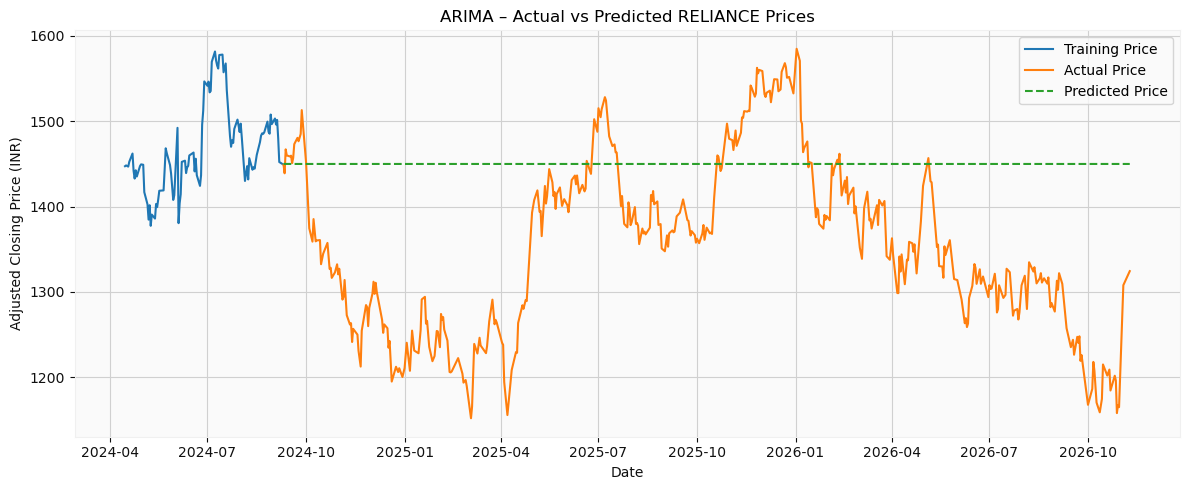

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(train.index[-100:], train.iloc[-100:], label="Training Price")
plt.plot(test.index, test, label="Actual Price")
plt.plot(test_predictions.index, test_predictions, "--", label="Predicted Price")

plt.title("ARIMA – Actual vs Predicted RELIANCE Prices")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (INR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#Forecast the Next 30 Trading Days

C:\Users\gauta\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\gauta\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Next 30 Trading-Day Forecast:
2026-11-10    1324.41
2026-11-11    1324.41
2026-11-12    1324.41
2026-11-13    1324.41
2026-11-16    1324.41
2026-11-17    1324.41
2026-11-18    1324.41
2026-11-19    1324.41
2026-11-20    1324.41
2026-11-23    1324.41
2026-11-24    1324.41
2026-11-25    1324.41
2026-11-26    1324.41
2026-11-27    1324.41
2026-11-30    1324.41
2026-12-01    1324.41
2026-12-02    1324.41
2026-12-03    1324.41
2026-12-04    1324.41
2026-12-07    1324.41
2026-12-08    1324.41
2026-12-09    1324.41
2026-12-10    1324.41
2026-12-11    1324.41
2026-12-14    1324.41
2026-12-15    1324.41
2026-12-16    1324.41
2026-12-17    1324.41
2026-12-18    1324.41
2026-12-21    1324.41
Freq: B, dtype: float64


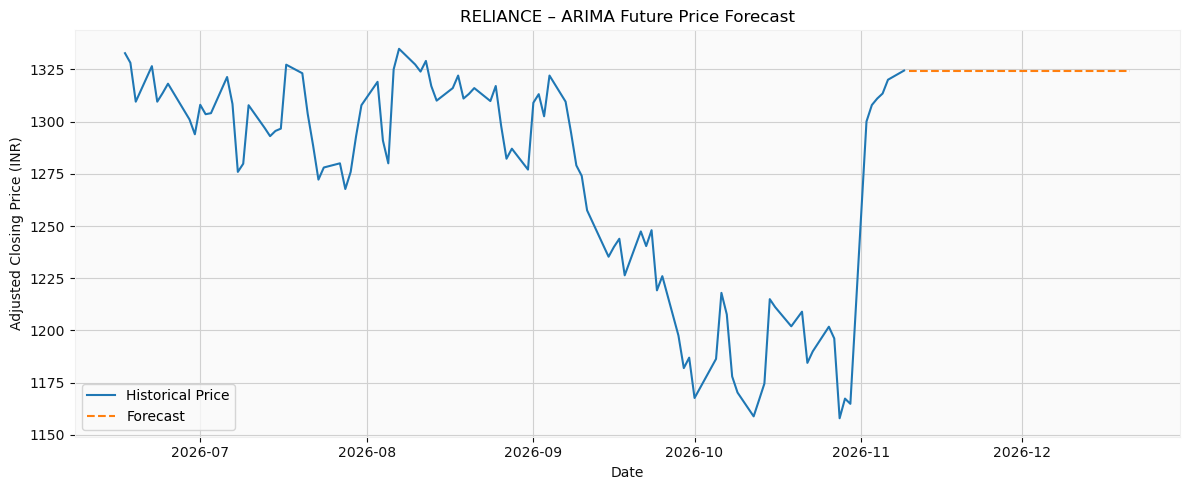

In [13]:
# Fit the model again using all available historical prices
final_model = ARIMA(pd.Series(prices.values), order=(1, 1, 1))
final_model_fit = final_model.fit()

future_values = final_model_fit.forecast(steps=30)

# Approximate future business dates (weekends excluded; exchange holidays are not included)
future_dates = pd.bdate_range(
    start=prices.index[-1] + pd.Timedelta(days=1),
    periods=30
)

future_forecast = pd.Series(np.asarray(future_values), index=future_dates)

print("Next 30 Trading-Day Forecast:")
print(future_forecast.round(2))

plt.figure(figsize=(12, 5))
plt.plot(prices.index[-100:], prices.iloc[-100:], label="Historical Price")
plt.plot(future_forecast.index, future_forecast, "--", label="Forecast")
plt.title("RELIANCE – ARIMA Future Price Forecast")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (INR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()